In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/: add the project root to the path to import src.
sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pandas as pd

from src.data.wrds_loader import WRDSOptionLoader

loader = WRDSOptionLoader()
raw_conn = loader._connection.connection.connection  # underlying psycopg2 connection


def run_query(sql: str, params: dict | None = None) -> pd.DataFrame:
    return loader._run_query(sql, params)
    try:
        with raw_conn.cursor() as cur:
            cur.execute(sql, params)
            columns = [col[0] for col in cur.description]
            return pd.DataFrame(cur.fetchall(), columns=columns)
    except Exception:
        raw_conn.rollback()  # reset the connection state after a failed query
        raise


# 1. SPX identifier in OptionMetrics
print(run_query("SELECT secid, ticker, issuer FROM optionm.secnmd WHERE ticker = 'SPX'"))

# 2. Columns of the tables we need
for table in ["opprcd2025", "secprd2025", "zerocd"]:
    print(f"\n=== {table} ===")
    print(
        run_query(
            """
            SELECT column_name, data_type
            FROM information_schema.columns
            WHERE table_schema = 'optionm' AND table_name = %(table)s
            ORDER BY ordinal_position
            """,
            {"table": table},
        )
    )

Loading library list...
Done
      secid ticker               issuer
0  108105.0    SPX  NEW S & P 500 INDEX
1  108105.0    SPX  NEW S & P 500 INDEX
2  108105.0    SPX  NEW S & P 500 INDEX
3  108105.0    SPX  NEW S & P 500 INDEX
4  108105.0    SPX  NEW S & P 500 INDEX
5  108105.0    SPX   CBOE S&P 500 INDEX

=== opprcd2025 ===
         column_name          data_type
0              secid   double precision
1               date               date
2             symbol  character varying
3        symbol_flag  character varying
4             exdate               date
5          last_date               date
6            cp_flag  character varying
7       strike_price   double precision
8           best_bid   double precision
9         best_offer   double precision
10            volume   double precision
11     open_interest   double precision
12   impl_volatility   double precision
13             delta   double precision
14             gamma   double precision
15              vega   double p

In [3]:
from datetime import datetime

SPX_SECID = 108105


def query_raw_surface(date: datetime, min_maturity: int, max_maturity: int) -> pd.DataFrame:
    table = f"optionm.opprcd{date.year}"
    sql = f"""
        SELECT
            date, exdate, (exdate - date) AS maturity_days,
            cp_flag, strike_price, best_bid, best_offer,
            volume, open_interest, impl_volatility,
            forward_price, am_settlement, expiry_indicator, root
        FROM {table}
        WHERE secid = %(secid)s
          AND date = %(date)s
          AND (exdate - date) BETWEEN %(min_m)s AND %(max_m)s
    """
    params = {
        "secid": SPX_SECID,
        "date": date.date(),
        "min_m": min_maturity,
        "max_m": max_maturity,
    }
    return run_query(sql, params)


raw = query_raw_surface(datetime(2025, 3, 3), 15, 45)
print(raw.shape)
print(raw["exdate"].value_counts().sort_index())
raw.head()

(8652, 14)
exdate
2025-03-18     356
2025-03-19     352
2025-03-20     340
2025-03-21    1704
2025-03-24     294
2025-03-25     296
2025-03-26     290
2025-03-27     276
2025-03-28     484
2025-03-31     916
2025-04-01     220
2025-04-02     188
2025-04-03     182
2025-04-04     434
2025-04-07     136
2025-04-08     132
2025-04-09     132
2025-04-11     320
2025-04-17    1600
Name: count, dtype: int64


,date,exdate,maturity_days,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,forward_price,am_settlement,expiry_indicator,root
0,2025-03-03,2025-03-21,18,C,1000000.0,4837.0,4855.10,0.0,21632.0,NaN,None,1.0,NaN,None
1,2025-03-03,2025-03-21,18,C,10000000.0,0.0,0.15,0.0,4.0,0.712318,None,1.0,NaN,None
2,2025-03-03,2025-03-21,18,C,10400000.0,0.0,0.15,0.0,0.0,0.759957,None,1.0,NaN,None
3,2025-03-03,2025-03-21,18,C,10800000.0,0.0,0.15,0.0,0.0,0.805513,None,1.0,NaN,None
4,2025-03-03,2025-03-21,18,C,10900000.0,0.0,0.15,0.0,0.0,0.816598,None,1.0,NaN,None


In [4]:
from src.data.wrds_loader import _MIN_OPEN_INTEREST, _MIN_VOLUME

step1 = raw[raw["best_bid"] > 0]
step2 = step1[(step1["volume"] >= _MIN_VOLUME) | (step1["open_interest"] >= _MIN_OPEN_INTEREST)]
step3 = step2[step2["best_offer"] > step2["best_bid"]]

summary = pd.DataFrame(
    {
        "rule": ["Raw surface", "1. bid > 0", "2. volume or OI >= 10", "3. ask > bid"],
        "remaining": [len(raw), len(step1), len(step2), len(step3)],
    }
)
summary["removed"] = -summary["remaining"].diff().fillna(0).astype(int)
print(summary)

# Sanity check: the production method gives the same result as the step-by-step version
clean = WRDSOptionLoader._apply_quantitative_filters(raw)
assert len(clean) == len(step3)
print(f"\nClean surface: {len(clean)} options")
clean.head()

                    rule  remaining  removed
0            Raw surface       8652        0
1             1. bid > 0       8478      174
2  2. volume or OI >= 10       4858     3620
3           3. ask > bid       4858        0

Clean surface: 4858 options


,date,exdate,maturity_days,option_type,strike,bid,ask,volume,open_interest,impl_volatility,forward_price,am_settlement,expiry_indicator,root,mid_price
0,2025-03-03,2025-03-21,18,C,200.0,5635.0,5652.3,1.0,51.0,NaN,None,1.0,NaN,None,5643.65
1,2025-03-03,2025-03-21,18,C,200.0,5633.1,5650.1,2.0,231.0,NaN,None,0.0,NaN,None,5641.60
2,2025-03-03,2025-04-17,45,C,200.0,5631.9,5650.2,0.0,19.0,NaN,None,0.0,NaN,None,5641.05
3,2025-03-03,2025-04-17,45,C,400.0,5434.4,5451.7,0.0,38.0,NaN,None,1.0,NaN,None,5443.05
4,2025-03-03,2025-03-21,18,C,400.0,5433.7,5453.5,0.0,10.0,NaN,None,0.0,NaN,None,5443.60


In [5]:
def strike_coverage(df: pd.DataFrame) -> pd.Series:
    puts = df[df["cp_flag"] == "P"]
    calls = df[df["cp_flag"] == "C"]
    return pd.Series(
        {
            "n_options": len(df),
            "n_expiries": df["exdate"].nunique(),
            "min_put_strike": puts["strike_price"].min() / 1000,
            "max_call_strike": calls["strike_price"].max() / 1000,
        }
    )


liquid_or = (step1["volume"] >= _MIN_VOLUME) | (step1["open_interest"] >= _MIN_OPEN_INTEREST)
liquid_and = (step1["volume"] >= _MIN_VOLUME) & (step1["open_interest"] >= _MIN_OPEN_INTEREST)

comparison = pd.DataFrame(
    {
        "bid > 0 only": strike_coverage(step1),
        "OR (current)": strike_coverage(step1[liquid_or]),
        "AND": strike_coverage(step1[liquid_and]),
    }
).T
print(comparison)

# Which expiries lose the most options under the OR rule?
removed = step1[~liquid_or]
print("\nOptions removed by rule 2, per expiry:")
print(removed["exdate"].value_counts().sort_index())

              n_options  n_expiries  min_put_strike  max_call_strike
bid > 0 only     8478.0        19.0          1200.0           8000.0
OR (current)     4858.0        19.0          1200.0           8000.0
AND              2041.0        18.0          1800.0           7000.0

Options removed by rule 2, per expiry:
exdate
2025-03-18    170
2025-03-19    183
2025-03-20    166
2025-03-21    465
2025-03-24    143
2025-03-25    181
2025-03-26    191
2025-03-27    185
2025-03-28    175
2025-03-31    253
2025-04-01    132
2025-04-02    123
2025-04-03    130
2025-04-04    161
2025-04-07    100
2025-04-08    121
2025-04-09    123
2025-04-11    133
2025-04-17    485
Name: count, dtype: int64


## Findings (2025-03-03, maturities 15–45 days)

- Raw surface: 8,652 SPX options across 19 expiries.
- Rule 1 (bid > 0) removes 174 options. Rule 3 (ask > bid) removes none: OptionMetrics already cleans crossed quotes, so the rule acts as a safeguard.
- Rule 2 (volume ≥ 10 **or** OI ≥ 10) removes 3,620 options (43%).
- **Aggregated across expiries**, rule 2 preserves the full strike range (1,200–8,000), because monthly expiries carry deep strikes with large open interest.
- **Per expiry, rule 2 truncates the OTM tails of weekly expiries.** For the 30-day expiry (2025-04-02), filtered puts stop around 3,000 (raw: ~2,400) and filtered calls stop around 6,300 (raw: ~7,800). The removed ITM options are irrelevant for the SVIX, but the removed OTM tails bias the SVIX integral downward.
- An AND condition would truncate even further (aggregate min put strike 1,200 → 1,800, one expiry lost). The OR condition is therefore retained.

## Open points (next PRs)

- Tail truncation of weekly expiries by the liquidity threshold (see above): to be quantified once the SVIX calculator is available.
- `forward_price` and `root` are empty in OptionMetrics: the forward must be computed in `_extract_macro_state`.
- Monthly expiries contain both SPX (AM-settled) and SPXW (PM-settled) series at the same strikes: one series must be selected per expiry in `get_interpolation_chains` to avoid double counting.
- `wrds` 3.1.6 pins SQLAlchemy 1.4, incompatible with pandas 3: `raw_sql` fails, so queries go through the underlying psycopg2 connection.

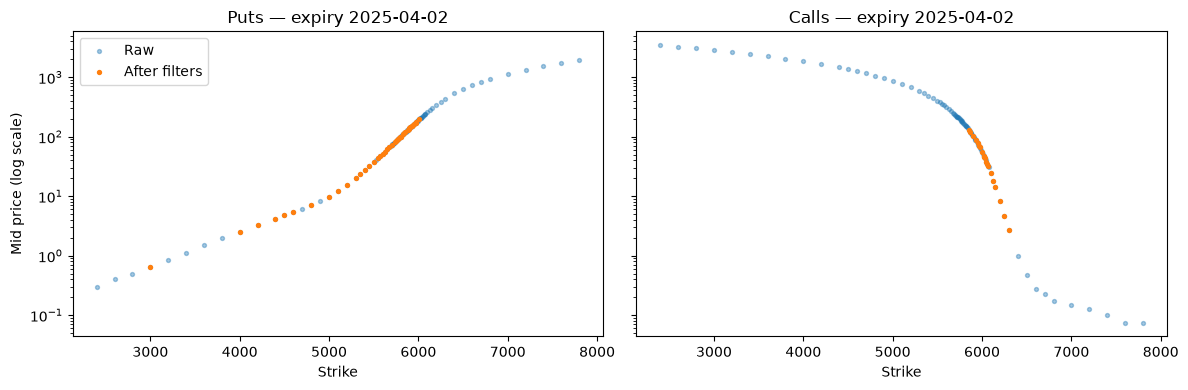

In [6]:
import matplotlib.pyplot as plt

target_exdate = pd.Timestamp("2025-04-02").date()  # 30-day maturity

raw_exp = raw[raw["exdate"] == target_exdate].copy()
raw_exp["strike"] = raw_exp["strike_price"] / 1000
raw_exp["mid_price"] = (raw_exp["best_bid"] + raw_exp["best_offer"]) / 2
clean_exp = clean[clean["exdate"] == target_exdate]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (flag, label) in zip(axes, [("P", "Puts"), ("C", "Calls")], strict=True):
    r = raw_exp[raw_exp["cp_flag"] == flag]
    c = clean_exp[clean_exp["option_type"] == flag]
    ax.scatter(r["strike"], r["mid_price"], s=8, alpha=0.4, label="Raw")
    ax.scatter(c["strike"], c["mid_price"], s=8, label="After filters")
    ax.set_yscale("log")
    ax.set_title(f"{label} — expiry {target_exdate}")
    ax.set_xlabel("Strike")
axes[0].set_ylabel("Mid price (log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()